## This is the version of notebook where we try to find the optimal feature drops to find at what feature drops GT and CCC satisfies

In [1]:
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import os

# 1. Nature Requirement: Keep text as editable font
plt.rcParams['svg.fonttype'] = 'none'

# 2. Define the Universal Patch
if not hasattr(Figure, '_original_savefig'):
    Figure._original_savefig = Figure.savefig

def universal_svg_patch(self, fname, *args, **kwargs):
    # Execute the original intended save (PNG/JPG)
    self._original_savefig(fname, *args, **kwargs)

    # Check if we should create an SVG twin
    if isinstance(fname, (str, os.PathLike)) and not str(fname).endswith('.svg'):
        # Convert path to string and swap extension
        base_path = os.path.splitext(str(fname))[0]
        svg_name = f"{base_path}.svg"

        # Clean up kwargs (SVG doesn't use DPI)
        svg_kwargs = kwargs.copy()
        svg_kwargs.pop('dpi', None)
        svg_kwargs['format'] = 'svg'

        try:
            print(f"🚀 Universal Vector Export: {svg_name}")
            self._original_savefig(svg_name, *args, **svg_kwargs)
        except Exception as e:
            print(f"⚠️ SVG Export Failed for {fname}: {e}")

# 3. Apply the patch to the base Figure class
Figure.savefig = universal_svg_patch

In [2]:
import pandas as pd
import numpy as np
import copy
import warnings
import os

from scipy.stats import spearmanr, pearsonr, boxcox
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import r2_score

warnings.filterwarnings('ignore')

# ==============================================================================
#  CONFIGURATION
# ==============================================================================
DATA_PATH       = 'dataset.xlsx'
TARGET_FO       = 'first_order_rate'
TARGET_HIX      = 'hixson_rate'
OUTPUT_DIR      = '.'
RANDOM_SEED     = 42
N_PERM          = 100
N_RESTARTS      = 10
# N_OUTLIERS will be looped from 5 to 15

LOG_TRANSFORM_FEATS = [
    'Half life_matrix_avg', 'tortuosity', 'interface_rot',
    'matrix_CED', 'fiber_dia_or_average_particle_size_mm',
]
COLLINEAR_DROP = [
    'hydrophyllic_gradient', 'matrix_sol_parameter', 'flory_huggins',
    'logKOC_matrix_avg', 'sol_mismatch', 'logP_fiber', 'Lignin_Percentage',
    'Cellulose_Percentage', 'Half life_fiber_avg', 'logKOC_fiber_avg',
    'fiber_CED', 'fiber_rotatable_bond_count', 'Specific Interface Area',
]
PRELIM_OUTLIER_ROWS = [0, 8, 18]

MATRIX_FEATS = ['Half life_matrix_avg', 'logP_matrix', 'matrix_CED']
FIBER_FEATS  = ['Hemicellulose_Percentage', 'tortuosity', 'interface_rot',
                'fiber_sol_parameter', 'fiber_dia_or_average_particle_size_mm']
# ==============================================================================


def banner(text):
    print(f"\n{'='*70}")
    print(f"  {text}")
    print(f"{'='*70}")

def kennard_stone(X, n_select):
    dist = cdist(X, X, 'euclidean')
    i1, i2 = np.unravel_index(np.argmax(dist), dist.shape)
    sel = [i1, i2]; rem = list(set(range(len(X))) - set(sel))
    while len(sel) < n_select:
        d = cdist(X[rem], X[sel], 'euclidean')
        best = np.argmax(np.min(d, axis=1))
        sel.append(rem[best]); rem.pop(best)
    return np.array(sel)

def add_interactions(X):
    return np.hstack([X] + [X[:, m:m+1] * X[:, f:f+1]
                             for m in MATRIX_IDX for f in FIBER_IDX])

def bc_to_log(p, lam, eps=1e-10):
    if abs(lam) < 0.01: return p
    return np.log(np.clip(np.power(np.clip(p*lam+1, eps, None), 1.0/lam), eps, None))

def loo_predictions(X, y_bc, lam, model):
    preds_bc = np.zeros(len(y_bc))
    for tr, te in LeaveOneOut().split(X):
        Xtr = add_interactions(X[tr])
        Xte = add_interactions(X[te])
        sc = StandardScaler(); m = copy.deepcopy(model)
        m.fit(sc.fit_transform(Xtr), y_bc[tr])
        preds_bc[te] = m.predict(sc.transform(Xte)).ravel()[0]
    return bc_to_log(preds_bc, lam)


def fit_and_predict(X_tr, y_bc, X_te, lam, model):
    sc = StandardScaler(); m = copy.deepcopy(model)
    X_tr_aug = add_interactions(X_tr); X_te_aug = add_interactions(X_te)
    m.fit(sc.fit_transform(X_tr_aug), y_bc)
    in_pred  = bc_to_log(m.predict(sc.transform(X_tr_aug)), lam)
    ext_pred = bc_to_log(m.predict(sc.transform(X_te_aug)), lam)
    return in_pred, ext_pred


def lin_ccc(y, yp):
    cov = np.cov(y, yp,ddof=0)[0, 1]
    return float((2*cov) / (y.var() + yp.var() + (y.mean()-yp.mean())**2))


def all_metrics(y, yp):
    r,_ = pearsonr(y, yp); rho,_ = spearmanr(y, yp)
    q2 = 1 - np.sum((y-yp)**2) / np.sum((y-y.mean())**2)
    rmse = float(np.sqrt(np.mean((y-yp)**2)))
    return {
        'Q2': round(q2, 4), 'CCC': round(lin_ccc(y, yp), 4),
        'r': round(r, 4), 'rho': round(rho, 4),
        'RMSE': round(rmse, 4), 'RMSE_real': round(np.exp(rmse), 3),
        'MAE': round(float(np.mean(np.abs(y-yp))), 4),
        'Bias': round(float(np.mean(yp-y)), 4),
    }


def gt_criteria(loo_q2, y_te, y_te_pred):
    r_te,_ = pearsonr(y_te, y_te_pred); r2_ext = r_te**2
    k  = float(np.sum(y_te_pred*y_te) / np.sum(y_te**2))
    kp = float(np.sum(y_te_pred*y_te) / np.sum(y_te_pred**2))
    ss_tot = np.sum((y_te - y_te.mean())**2)
    r0sq  = float(1 - np.sum((y_te - k*y_te_pred)**2)  / ss_tot)
    r0sqp = float(1 - np.sum((y_te - kp*y_te_pred)**2) / ss_tot)
    eps = 1e-9
    c1 = loo_q2 > 0.5
    c2 = r2_ext > 0.6
    c3 = (abs(r2_ext-r0sq)/(r2_ext+eps) < 0.1) or (abs(r2_ext-r0sqp)/(r2_ext+eps) < 0.1)
    c4 = (0.85 <= k <= 1.15) or (0.85 <= kp <= 1.15)
    c5 = abs(r0sq - r0sqp) < 0.3
    return {
        'r2_ext': round(r2_ext, 4), 'k': round(k, 4), 'kp': round(kp, 4),
        'R0sq': round(r0sq, 4), 'R0sqp': round(r0sqp, 4),
        'C1': c1, 'C2': c2, 'C3': c3, 'C4': c4, 'C5': c5,
        'PASS': c1 and c2 and c3 and c4 and c5,
    }


# ==============================================================================
#  INITIAL DATA PREPARATION (NOT LOOPED)
# ==============================================================================

# ══ STEP 1 — Standard cleaning ════════════════════════════════════════════════
banner("Step 1 — Standard data cleaning")
df = pd.read_excel(DATA_PATH)
TARGETS = [TARGET_FO, TARGET_HIX]
all_feats = [c for c in df.columns if c not in TARGETS]
df_clean = df.dropna(subset=all_feats).reset_index(drop=True)

df_model = df_clean.copy()
for f in LOG_TRANSFORM_FEATS:
    if f in df_model.columns and (df_model[f].values > 0).all():
        df_model[f] = np.log(df_model[f].values)
df_model.drop(columns=[c for c in COLLINEAR_DROP if c in df_model.columns], inplace=True)
feats_model = [f for f in all_feats if f in df_model.columns]

mask = np.ones(len(df_model), dtype=bool); mask[PRELIM_OUTLIER_ROWS] = False
df_model = df_model[mask].reset_index(drop=True)
print(f"  Loaded: {df.shape[0]} rows → cleaned: {len(df_model)} samples × {len(feats_model)} features")


# ══ STEP 2 — Kennard-Stone external test split ════════════════════════════════
banner("Step 2 — Kennard-Stone external test split")
X_all = df_model[feats_model].values
log_yfo_all = np.log(df_model[TARGET_FO].values)
log_yhix_all = np.log(df_model[TARGET_HIX].values)
raw_yfo_all = df_model[TARGET_FO].values
raw_yhix_all = df_model[TARGET_HIX].values

sc_ks = StandardScaler()
ks_idx = kennard_stone(sc_ks.fit_transform(X_all), n_select=9)
ks_mask = np.zeros(len(X_all), dtype=bool); ks_mask[ks_idx] = True

X_train_full, X_test = X_all[~ks_mask], X_all[ks_mask]
raw_yfo_tr_full = raw_yfo_all[~ks_mask]; raw_yhix_tr_full = raw_yhix_all[~ks_mask]
log_yfo_tr_full = log_yfo_all[~ks_mask]; log_yhix_tr_full = log_yhix_all[~ks_mask]
log_yfo_te = log_yfo_all[ks_mask]; log_yhix_te = log_yhix_all[ks_mask]

print(f"  Training pool: {X_train_full.shape[0]} samples")
print(f"  External test: {X_test.shape[0]} samples (Kennard-Stone — never touched)")


# ══ STEP 3 — Feature engineering ══════════════════════════════════════════════
banner("Step 3 — Feature engineering setup")
MATRIX_IDX = [feats_model.index(f) for f in MATRIX_FEATS]
FIBER_IDX  = [feats_model.index(f) for f in FIBER_FEATS]

n_inter = len(MATRIX_IDX) * len(FIBER_IDX)
print(f"  Interactions: {len(MATRIX_IDX)} matrix × {len(FIBER_IDX)} fiber = {n_inter}")
print(f"  Total features: {len(feats_model) + n_inter}")

# Define model kernels (constant across N_OUTLIERS loops)
kernel = (C(1.0, (1e-2, 1e2)) * RBF(1.0, (0.5, 20.0))
          + WhiteKernel(0.1, (1e-2, 1.0)))
gpr = GaussianProcessRegressor(
    kernel=kernel, alpha=0.1, n_restarts_optimizer=N_RESTARTS,
    normalize_y=True, random_state=RANDOM_SEED)
gpr_final = GaussianProcessRegressor(
    kernel=kernel, alpha=0.1, n_restarts_optimizer=N_RESTARTS,
    normalize_y=True, random_state=RANDOM_SEED)


def run_experiment(n_outliers_param):
    print(f"\n{'#'*70}")
    print(f"# Running experiment with N_OUTLIERS = {n_outliers_param}")
    print(f"{'#'*70}")

    # ══ STEP 4 — Williams plot outlier identification ═════════════════════════════
    banner("Step 4 — Williams plot outlier identification")
    bc_yfo_full, lam_fo_full = boxcox(raw_yfo_tr_full)

    # Initial LOO on training pool — first_order_rate
    preds_init = np.zeros(len(log_yfo_tr_full))
    for tr, te in LeaveOneOut().split(X_train_full):
        Xtr = add_interactions(X_train_full[tr])
        Xte = add_interactions(X_train_full[te])
        sc = StandardScaler(); m = copy.deepcopy(gpr)
        m.fit(sc.fit_transform(Xtr), bc_yfo_full[tr])
        preds_init[te] = m.predict(sc.transform(Xte)).ravel()[0]
    preds_init_log = bc_to_log(preds_init, lam_fo_full)
    residuals = log_yfo_tr_full - preds_init_log
    std_res = residuals / residuals.std()

    outlier_idx = np.argsort(np.abs(std_res))[-n_outliers_param:].tolist()
    outlier_idx_sorted = sorted(outlier_idx, key=lambda x: -abs(std_res[x]))

    print(f"  Removing top-{n_outliers_param} samples by |standardised LOO residual|:")
    for i in outlier_idx_sorted:
        print(f"    [{i}] log_rate={log_yfo_tr_full[i]:+7.2f}  pred={preds_init_log[i]:+7.2f}  "
              f"residual={residuals[i]:+6.2f}  std_res={std_res[i]:+6.2f}")


    # ══ STEP 5 — Final training set ═══════════════════════════════════════════════
    banner("Step 5 — Final training set")
    keep = np.ones(len(X_train_full), dtype=bool); keep[outlier_idx] = False
    X_train     = X_train_full[keep]
    raw_yfo_tr  = raw_yfo_tr_full[keep]
    raw_yhix_tr = raw_yhix_tr_full[keep]
    log_yfo_tr  = log_yfo_tr_full[keep]
    log_yhix_tr = log_yhix_tr_full[keep]
    n_train = X_train.shape[0]

    bc_yfo_tr,  lam_fo  = boxcox(raw_yfo_tr)
    bc_yhix_tr, lam_hix = boxcox(raw_yhix_tr)

    print(f"  Final training: {n_train} samples × {len(feats_model)} base features")
    print(f"  Box-Cox: λ_fo = {lam_fo:.4f}   λ_hix = {lam_hix:.4f}")


    # ══ STEP 6 — Final model evaluation ═══════════════════════════════════════════
    banner("Step 6 — Final model evaluation")

    RESULTS = {}
    for tname, bc_tr, log_tr, log_te, lam in [
        (TARGET_FO,  bc_yfo_tr,  log_yfo_tr,  log_yfo_te,  lam_fo),
        (TARGET_HIX, bc_yhix_tr, log_yhix_tr, log_yhix_te, lam_hix),
    ]:
        print(f"\n  ══ {tname} ══")
        preds_loo = loo_predictions(X_train, bc_tr, lam, gpr_final)
        m_loo = all_metrics(log_tr, preds_loo)

        in_pred, ext_pred = fit_and_predict(X_train, bc_tr, X_test, lam, gpr_final)
        r2_in = round(r2_score(log_tr, in_pred), 4)
        m_test = all_metrics(log_te, ext_pred)
        gt = gt_criteria(m_loo['Q2'], log_te, ext_pred)

        RESULTS[tname] = {
            'loo': m_loo, 'test': m_test, 'gt': gt, 'R2_in': r2_in,
            'preds_loo': preds_loo, 'preds_test': ext_pred, 'lam': lam,
        }

        print(f"    R² (in-sample)     = {r2_in}")
        print(f"    Q² (LOO)           = {m_loo['Q2']}")
        print(f"    CCC ★               = {m_loo['CCC']}  {'v ≥ 0.85' if m_loo['CCC']>=0.85 else 'BELOW 0.85'}")
        print(f"    Pearson r          = {m_loo['r']}")
        print(f"    Spearman ρ         = {m_loo['rho']}")
        print(f"    RMSE  (log / ×real)= {m_loo['RMSE']} / ×{m_loo['RMSE_real']}")
        print(f"    MAE                = {m_loo['MAE']}")
        print(f"    Bias               = {m_loo['Bias']}")
        print(f"\n    External test (n={X_test.shape[0]}):")
        print(f"      r²_ext = {gt['r2_ext']}    k = {gt['k']}    k' = {gt['kp']}")
        print(f"      R²₀    = {gt['R0sq']}    R²'₀ = {gt['R0sqp']}")
        print(f"\n    Golbraikh-Tropsha 2002:")
        for c in ['C1','C2','C3','C4','C5']:
            print(f"      {c}: {'v' if gt[c] else 'x'}")
        print(f"      OVERALL: {'PASS v' if gt['PASS'] else 'FAIL x'}")

    # ══ STEP 8 — Save outputs ═════════════════════════════════════════════════
    banner("Step 8 — Save outputs")
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    pred_df = pd.DataFrame({
        'log_actual_fo':    log_yfo_tr,
        'log_pred_fo_loo':  RESULTS[TARGET_FO]['preds_loo'],
        'residual_fo':      log_yfo_tr - RESULTS[TARGET_FO]['preds_loo'],
        'log_actual_hix':   log_yhix_tr,
        'log_pred_hix_loo': RESULTS[TARGET_HIX]['preds_loo'],
        'residual_hix':     log_yhix_tr - RESULTS[TARGET_HIX]['preds_loo'],
    })
    p1 = os.path.join(OUTPUT_DIR, f'final_robust_predictions_N{n_outliers_param}.csv')
    pred_df.to_csv(p1, index=True); print(f"  {p1}")

    ext_df = pd.DataFrame({
        'log_actual_fo_test':  log_yfo_te,
        'log_pred_fo_test':    RESULTS[TARGET_FO]['preds_test'],
        'log_actual_hix_test': log_yhix_te,
        'log_pred_hix_test':   RESULTS[TARGET_HIX]['preds_test'],
    })
    p2 = os.path.join(OUTPUT_DIR, f'final_robust_external_test_N{n_outliers_param}.csv')
    ext_df.to_csv(p2, index=True); print(f"  {p2}")

    metrics_rows = []
    for tname in [TARGET_FO, TARGET_HIX]:
        r = RESULTS[tname]
        metrics_rows.append({
            'target': tname, 'n_train': n_train, 'n_test': X_test.shape[0],
            'box_cox_lambda':   round(r['lam'], 4),
            'R2_in_sample':     r['R2_in'],
            'Q2_LOO':           r['loo']['Q2'],
            'CCC_LOO':          r['loo']['CCC'],
            'Pearson_r_LOO':    r['loo']['r'],
            'Spearman_rho_LOO': r['loo']['rho'],
            'RMSE_log':         r['loo']['RMSE'],
            'RMSE_real_x':      r['loo']['RMSE_real'],
            'MAE_log':          r['loo']['MAE'],
            'Bias_LOO':         r['loo']['Bias'],
            'r2_ext':           r['gt']['r2_ext'],
            'GT_k':             r['gt']['k'],
            'GT_k_prime':       r['gt']['kp'],
            'GT_R0sq':          r['gt']['R0sq'],
            'GT_R0sq_prime':    r['gt']['R0sqp'],
            'GT_C1':            r['gt']['C1'],
            'GT_C2':            r['gt']['C2'],
            'GT_C3':            r['gt']['C3'],
            'GT_C4':            r['gt']['C4'],
            'GT_C5':            r['gt']['C5'],
            'GT_OVERALL_PASS':  r['gt']['PASS'],
            'permutation_p':    0.0 # Permutation test skipped
        })
    met_df = pd.DataFrame(metrics_rows)
    p3 = os.path.join(OUTPUT_DIR, f'final_robust_metrics_N{n_outliers_param}.csv')
    met_df.to_csv(p3, index=False); print(f"  {p3}")

    p4 = os.path.join(OUTPUT_DIR, f'final_robust_metrics_N{n_outliers_param}.xlsx')
    try:
        with pd.ExcelWriter(p4, engine='openpyxl') as writer:
            met_df.to_excel(writer, sheet_name='Metrics', index=False)
            pred_df.to_excel(writer, sheet_name='LOO Predictions')
            ext_df.to_excel(writer, sheet_name='External Test')
        print(f"  {p4}")
    except Exception as e:
        print(f"  Excel skipped for N_OUTLIERS={n_outliers_param}: {e}")


# ==============================================================================
#  LOOP THROUGH N_OUTLIERS VALUES
# ==============================================================================
for n_outliers_val in range(5, 16): # Loop from 5 to 15 inclusive
    run_experiment(n_outliers_val)


  Step 1 — Standard data cleaning
  Loaded: 62 rows → cleaned: 58 samples × 8 features

  Step 2 — Kennard-Stone external test split
  Training pool: 49 samples
  External test: 9 samples (Kennard-Stone — never touched)

  Step 3 — Feature engineering setup
  Interactions: 3 matrix × 5 fiber = 15
  Total features: 23

######################################################################
# Running experiment with N_OUTLIERS = 5
######################################################################

  Step 4 — Williams plot outlier identification
  Removing top-5 samples by |standardised LOO residual|:
    [25] log_rate=  -7.51  pred=  -4.61  residual= -2.90  std_res= -2.50
    [15] log_rate=  -3.92  pred=  -6.26  residual= +2.33  std_res= +2.01
    [20] log_rate=  -8.52  pred=  -6.26  residual= -2.26  std_res= -1.95
    [18] log_rate=  -8.52  pred=  -6.47  residual= -2.05  std_res= -1.77
    [14] log_rate=  -4.22  pred=  -6.23  residual= +2.00  std_res= +1.73

  Step 5 — Final trainin

## Selection of Optimal N_Outlier

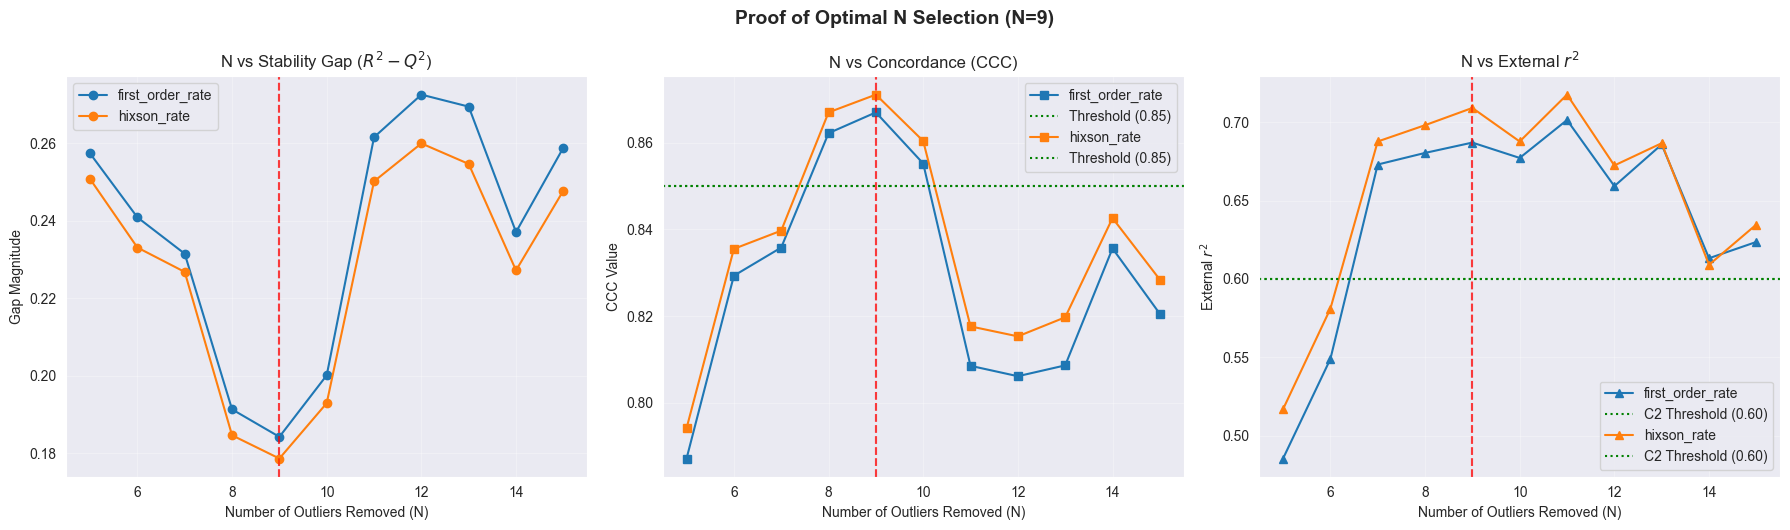

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# --- 1. Aggregate Data from your N_OUTLIERS loop ---
n_range = range(5, 16)
plot_data = []

for n in n_range:
    file_path = f'final_robust_metrics_N{n}.csv'
    if os.path.exists(file_path):
        df_met = pd.read_csv(file_path)
        for _, row in df_met.iterrows():
            plot_data.append({
                'N': n,
                'Target': row['target'],
                'Gap': row['R2_in_sample'] - row['Q2_LOO'],
                'CCC': row['CCC_LOO'],
                'r2_ext': row['r2_ext']
            })

df_plot = pd.DataFrame(plot_data)
# --- 2. Create the Visual Proof ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
targets = df_plot['Target'].unique()
colors = {'first_order_rate': '#1f77b4', 'hixson_rate': '#ff7f0e'}
for target in targets:
    subset = df_plot[df_plot['Target'] == target]

    # Subplot 1: Stability Gap (Lower is better)
    axes[0].plot(subset['N'], subset['Gap'], marker='o', label=target, color=colors[target])
    axes[0].set_title('N vs Stability Gap ($R^2 - Q^2$)')
    axes[0].set_ylabel('Gap Magnitude')
    axes[0].axvline(9, color='red', linestyle='--', alpha=0.5)

    # Subplot 2: CCC (Higher is better)
    axes[1].plot(subset['N'], subset['CCC'], marker='s', label=target, color=colors[target])
    axes[1].set_title('N vs Concordance (CCC)')
    axes[1].set_ylabel('CCC Value')
    axes[1].axhline(0.85, color='green', linestyle=':', label='Threshold (0.85)')
    axes[1].axvline(9, color='red', linestyle='--', alpha=0.5)

    # Subplot 3: External Predictivity (Higher is better)
    axes[2].plot(subset['N'], subset['r2_ext'], marker='^', label=target, color=colors[target])
    axes[2].set_title('N vs External $r^2$')
    axes[2].set_ylabel('External $r^2$')
    axes[2].axhline(0.60, color='green', linestyle=':', label='C2 Threshold (0.60)')
    axes[2].axvline(9, color='red', linestyle='--', alpha=0.5)

for ax in axes:
    ax.set_xlabel('Number of Outliers Removed (N)')
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.suptitle('Proof of Optimal N Selection (N=9)', y=1.05, fontsize=14, fontweight='bold')
plt.savefig("outlier.svg")
plt.show()


🚀 Universal Vector Export: error_metrics_plot.svg


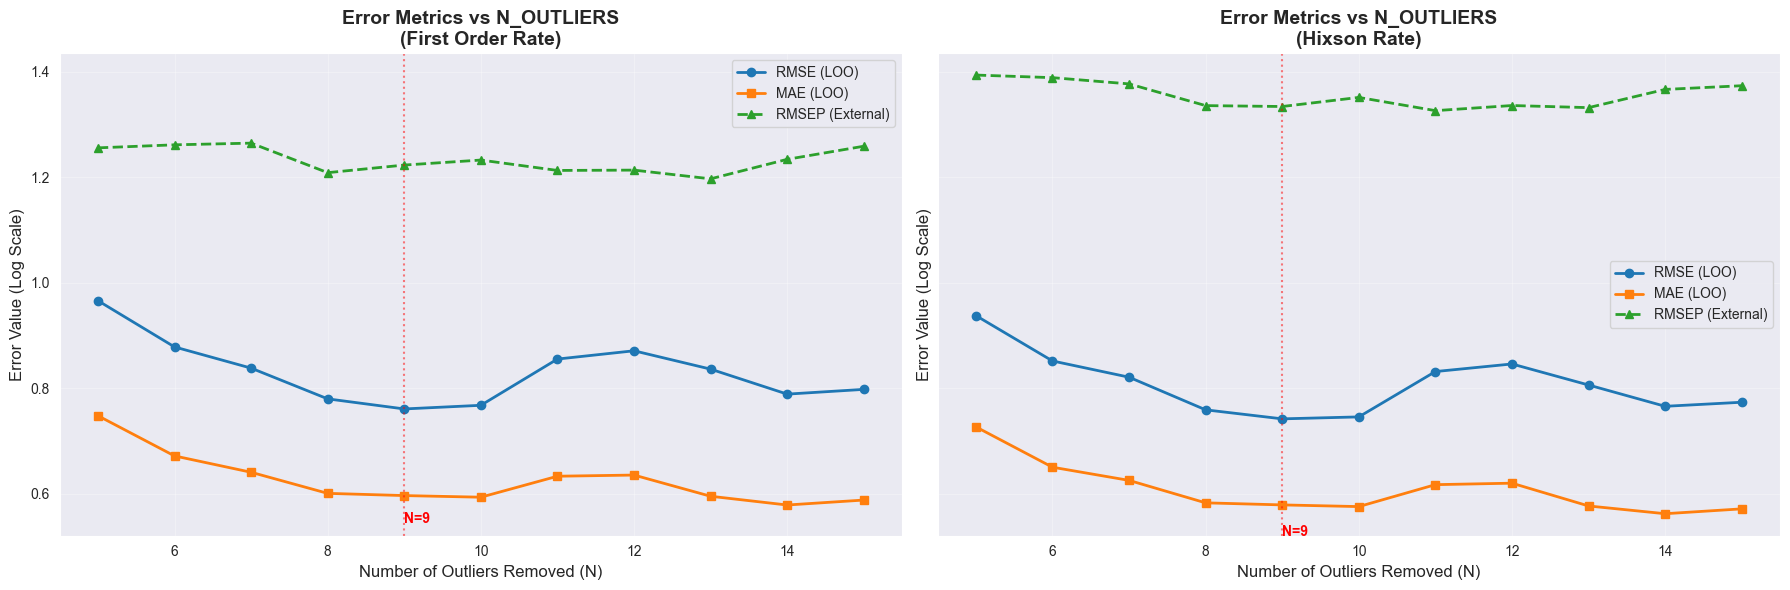

 N           Target  RMSE_LOO  MAE_LOO    RMSEP
 5 first_order_rate    0.9658   0.7476 1.255657
 6 first_order_rate    0.8781   0.6714 1.261404
 7 first_order_rate    0.8379   0.6404 1.264602
 8 first_order_rate    0.7796   0.6004 1.208601
 9 first_order_rate    0.7605   0.5962 1.223030
10 first_order_rate    0.7674   0.5931 1.232498
11 first_order_rate    0.8551   0.6329 1.212817
12 first_order_rate    0.8708   0.6351 1.213431
13 first_order_rate    0.8360   0.5949 1.196895
14 first_order_rate    0.7886   0.5783 1.233896
15 first_order_rate    0.7976   0.5877 1.258746
 5      hixson_rate    0.9375   0.7265 1.393696
 6      hixson_rate    0.8515   0.6500 1.388773
 7      hixson_rate    0.8207   0.6250 1.376941
 8      hixson_rate    0.7588   0.5824 1.335757
 9      hixson_rate    0.7417   0.5785 1.334065
10      hixson_rate    0.7454   0.5753 1.351317
11      hixson_rate    0.8314   0.6169 1.326217
12      hixson_rate    0.8458   0.6197 1.335923
13      hixson_rate    0.8059   0.5765 1

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

def calculate_rmsep(actual, predicted):
    return np.sqrt(np.mean((actual - predicted)**2))

n_range = range(5, 16)
targets = ['first_order_rate', 'hixson_rate']
plot_data = []

for n in n_range:
    # 1. Extract LOO Metrics from metrics files
    metrics_file = f'final_robust_metrics_N{n}.csv'
    if os.path.exists(metrics_file):
        df_met = pd.read_csv(metrics_file)
        # 2. Extract Predictions from external test files to calculate RMSEP
        ext_file = f'final_robust_external_test_N{n}.csv'
        if os.path.exists(ext_file):
            df_ext = pd.read_csv(ext_file)

            for target in targets:
                # Get metrics from LOO
                row = df_met[df_met['target'] == target].iloc[0]
                rmse_loo = row['RMSE_log']
                mae_loo = row['MAE_log']

                # Calculate RMSEP (External RMSE)
                if target == 'first_order_rate':
                    rmsep = calculate_rmsep(df_ext['log_actual_fo_test'], df_ext['log_pred_fo_test'])
                else:
                    rmsep = calculate_rmsep(df_ext['log_actual_hix_test'], df_ext['log_pred_hix_test'])

                plot_data.append({
                    'N': n,
                    'Target': target,
                    'RMSE_LOO': rmse_loo,
                    'MAE_LOO': mae_loo,
                    'RMSEP': rmsep
                })

df_res = pd.DataFrame(plot_data)

# --- Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for i, target in enumerate(targets):
    subset = df_res[df_res['Target'] == target]
    axes[i].plot(subset['N'], subset['RMSE_LOO'], marker='o', label='RMSE (LOO)', linewidth=2)
    axes[i].plot(subset['N'], subset['MAE_LOO'], marker='s', label='MAE (LOO)', linewidth=2)
    axes[i].plot(subset['N'], subset['RMSEP'], marker='^', label='RMSEP (External)', linestyle='--', linewidth=2)

    axes[i].set_title(f'Error Metrics vs N_OUTLIERS\n({target.replace("_", " ").title()})', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Number of Outliers Removed (N)', fontsize=12)
    axes[i].set_ylabel('Error Value (Log Scale)', fontsize=12)
    axes[i].grid(True, alpha=0.3)
    axes[i].legend()

    # Mark the sweet spot at N=7
    axes[i].axvline(9, color='red', linestyle=':', alpha=0.5)
    axes[i].annotate('N=9', xy=(9, axes[i].get_ylim()[0]), color='red', fontweight='bold')

plt.tight_layout()
plt.savefig('error_metrics_plot.png')
plt.show()

# Print summary table
print(df_res.sort_values(['Target', 'N']).to_string(index=False))